# SIMIND Introduction

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/SIMIND-Jaszak")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/SIMIND-Jaszak")

SPECT/SIMIND-Jaszak: already downloaded


In [2]:
import matplotlib.pyplot as plt
import torch
from pytomography import io
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.algorithms import OSEM
from pytomography.likelihoods import PoissonLogLikelihood
import os

In [3]:
# Paths are set in the data cell at the top of this tutorial
PATH = DATA / 'SPECT'
data_path = os.path.join(PATH, 'SIMIND-Jaszak', 'lu177_SYME_jaszak')

## 1. Opening Data

SIMIND writes one header file (`.h00`) for each energy window it records. This Lu-177 simulation recorded six: `tot_w1` is the 208 keV photopeak (187.2–228.8 keV), and `tot_w2` and `tot_w3` are the scatter windows just below and above it; `tot_w4` to `tot_w6` are the same three windows for the 113 keV photopeak. This tutorial reconstructs the 208 keV photopeak, the energy of the attenuation map and of the collimator response used below. We specify the header files of its three windows:

In [4]:
photopeak_path = os.path.join(data_path,'tot_w1.h00')  # the 208 keV photopeak
lower_path = os.path.join(data_path, 'tot_w2.h00')
upper_path = os.path.join(data_path, 'tot_w3.h00')

`io.SPECT.read_simind` reads the three windows in one call. It returns the projections and the metadata PyTomography keeps with them:
* `ObjectMeta`: voxel size (mm), image dimensions, and where the grid is (`frame='scanner'`: SIMIND data have no patient, so the grid is centred on the scanner's axis)
* `ProjMeta` (for SPECT): detector angles, radial positions (mm), detector pixel size/dimensions, and every energy window

In [5]:
projections, object_meta, proj_meta = io.SPECT.read_simind([photopeak_path, lower_path, upper_path])
for name, window in zip(['photopeak', 'lower', 'upper'], proj_meta.energy_windows):
    print(f'{name:9s} window: {window.lower:.1f}-{window.upper:.1f} keV')

photopeak window: 187.2-228.8 keV
lower     window: 166.4-187.2 keV
upper     window: 228.8-249.6 keV


In [6]:
object_meta

SPECTObjectMeta(dr=(4.8, 4.8, 4.8), shape=(128, 128, 128), centre=(0.0, 0.0, 0.0), frame='scanner', units=None, modality='NM')

In [7]:
proj_meta

acquisition_start = None
angles = tensor([  0.0000,   3.7500,   7.5000,  11.2500,  15.0000,  18.7500,  22.5000,
         26.2500,  30.0000,  33.7500,  37.5000,  41.2500,  45.0000,  48.7500,
         52.5000,  56.2500,  60.0000,  63.7500,  67.5000,  71.2500,  75.0000,
         78.7500,  82.5000,  86.2500,  90.0000,  93.7500,  97.5000, 101.2500,
        105.0000, 108.7500, 112.5000, 116.2500, 120.0000, 123.7500, 127.5000,
        131.2500, 135.0000, 138.7500, 142.5000, 146.2500, 150.0000, 153.7500,
        157.5000, 161.2500, 165.0000, 168.7500, 172.5000, 176.2500, 180.0000,
        183.7500, 187.5000, 191.2500, 195.0000, 198.7500, 202.5000, 206.2500,
        210.0000, 213.7500, 217.5000, 221.2500, 225.0000, 228.7500, 232.5000,
        236.2500, 240.0000, 243.7500, 247.5000, 251.2500, 255.0000, 258.7500,
        262.5000, 266.2500, 270.0000, 273.7500, 277.5000, 281.2500, 285.0000,
        288.7500, 292.5000, 296.2500, 300.0000, 303.7500, 307.5000, 311.2500,
        315.0000, 318.7500, 32

The projections hold the three windows, in the order of the header files: `[window, angle, r, z]`. The photopeak is the first:

In [8]:
photopeak = projections[0]
photopeak.shape

torch.Size([96, 128, 128])

This corresponds to 96 angles where each projection is 128x128. We can plot these projections as follows:

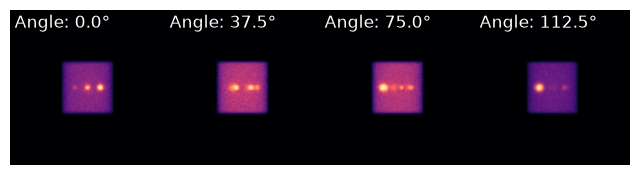

In [9]:
fig, ax = plt.subplots(1,4,figsize=(8,2.4), gridspec_kw={'wspace':0.0})
for i in range(4):
    ax[i].imshow(photopeak[10*i].cpu().T, cmap='magma')
    ax[i].axis('off')
    ax[i].text(0.03, 0.97, f'Angle: {proj_meta.angles[10*i]:.1f}°', ha='left', va='top', color='white', transform=ax[i].transAxes, fontsize=12)

Raw SIMIND data has units of Counts / Second / MBq and represents the *expectation value* of the measured data in each detector bin. We can generate clinically realistic data by 
1. scaling by time and activity (converting to units of counts)
2. obtaining a Poisson realization

In [10]:
activity = 1000 # MBq 
time_per_proj = 15 # s
photopeak_realization = torch.poisson(photopeak * activity * time_per_proj)

The actual data is noisier:

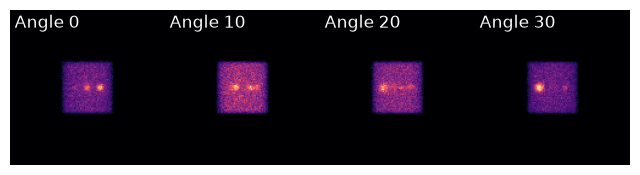

In [11]:
fig, ax = plt.subplots(1,4,figsize=(8,2.4), gridspec_kw={'wspace':0.0})
for i in range(4):
    ax[i].imshow(photopeak_realization[10*i].cpu().T, cmap='magma')
    ax[i].axis('off')
    ax[i].text(0.03, 0.97, f'Angle {10*i}', ha='left', va='top', color='white', transform=ax[i].transAxes, fontsize=12)

We can do similar things for the adjacent scatter windows:

In [12]:
lower_realization = torch.poisson(projections[1] * activity * time_per_proj)
upper_realization = torch.poisson(projections[2] * activity * time_per_proj)

These adjacent energy windows can be used to get an estimate for the scatter in the photopeak window via the triple energy window (TEW) technique. `io.SPECT.energy_window_scatter` takes the projections of every window, `[window, angle, r, z]`, and the windows' widths from `proj_meta`:

In [13]:
realizations = torch.stack([photopeak_realization, lower_realization, upper_realization])
scatter_estimate_TEW = io.SPECT.energy_window_scatter(realizations, proj_meta, peak=0, lower=1, upper=2)

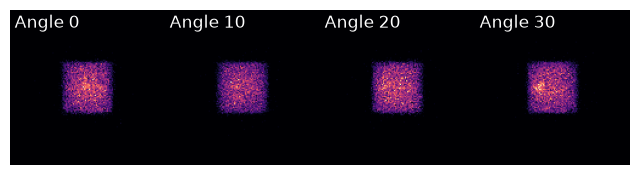

In [14]:
fig, ax = plt.subplots(1,4,figsize=(8,2.4), gridspec_kw={'wspace':0.0})
for i in range(4):
    ax[i].imshow(scatter_estimate_TEW[10*i].cpu().T, cmap='magma')
    ax[i].axis('off')
    ax[i].text(0.03, 0.97, f'Angle {10*i}', ha='left', va='top', color='white', transform=ax[i].transAxes, fontsize=12)

## 2. Creating the System Matrix

The SPECT system matrix depends on modeling (i) attenuation and (ii) collimator detector response (or point spread function)

### 2.1 Attenuation Modeling

For attenuation modeling we need the corresponding attenuation map. `io.attenuation_map` reads the one SIMIND generated and puts it on the reconstruction grid, in 1/mm. SIMIND's header doesn't record how the map's axes are laid out (simind.ini index 22), so `layout=` says it: `'mu'` for this simulation (index 22 = 3). SIMIND writes the map at the simulation's photon energy, here 208 keV (0.0135 /mm in water), so it matches the photopeak we reconstruct: `energy`, the photon energy of the window, is checked against the map's water. Reconstructing another window, such as the 113 keV photopeak, would need an attenuation map and a collimator response at that energy.

In [15]:
path_amap = os.path.join(data_path, 'amap.hct')
amap = io.attenuation_map(path_amap, object_meta, energy=proj_meta.energy_windows[0].photon_energy, layout='mu')

We can plot a 3D axial slice of this phantom (cylinder) as follows:

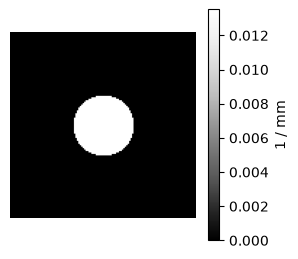

In [16]:
plt.figure(figsize=(3,3))
plt.imshow(amap[:,:,64].cpu().T, cmap='Greys_r')
plt.axis('off')
plt.colorbar(label='1 / mm')

From this attenuation map we build a `SPECTAttenuationTransform`, which will eventually be used in creating the system matrix

In [17]:
att_transform = SPECTAttenuationTransform(amap)

### 2.2 Collimator Detector Response (or Point Spread Function) Modeling

A perfect SPECT detector would only allow photons travelling perpendicular to the collimator holes to be detected: in practice this is not the case. The angle at which photons can enter depends on the collimator/scintillator parameters. `io.SPECT.simind_psf` gets the metadata from the header: it uses the collimator's dimensions written in the header, at the photon energy of the header's window (208.4 keV, Lu-177's line). Its lengths are in mm.

* The information gives the function/parameters for the point spread function, which depends on the distance between the source/detector $r$: its width is $\sigma(r) = \sqrt{(ar+b)^2+c^2}$, with $r$, $b$ and $c$ in mm (`sigma_fit_params` are $a$, $b$, $c$)

In [18]:
psf_meta = io.SPECT.simind_psf(photopeak_path)
# Below is optional to print details about psf_meta
print(psf_meta)

kernel_dimensions = 2D
min_sigmas = 3
shape = gaussian
sigma_fit_params = [np.float64(0.031622284625755115), np.float64(1.248503046423388), np.float64(1.253025580712328)]



As before, we create a `Transform` with this metadata, which we will soon provide to the system matrix

In [19]:
psf_transform = SPECTPSFTransform(psf_meta)

### 2.3 Creating the system matrix

The `SPECTSystemMatrix` requires the `metadata` as well as transforms derived previously. In this case we use attenuation and PSF modeling

In [20]:
system_matrix = SPECTSystemMatrix(
        obj2obj_transforms = [att_transform,psf_transform],
        proj2proj_transforms = [],
        object_meta = object_meta,
        proj_meta = proj_meta
    )

## 3 Likelihood / Reconstruction

The likelihood function for SPECT/PET is the `PoissonLogLikelihood`:
* It gives the relative probability of measuring `projections` given `system_matrix`, an additive term `scatter_estimate_TEW`, and an object estimate (not specified in creating an instance of the class)

In [21]:
likelihood = PoissonLogLikelihood(
    system_matrix = system_matrix,
    projections = photopeak_realization,
    additive_term = scatter_estimate_TEW
)

We can use the likelihood in image reconstruction, in this case we'll use the ordered subset expectation maximum (OSEM) algorithm. We initialize it as follows, and `estimate_memory` says how much RAM and GPU memory it will need with 8 subsets before it runs:

In [22]:
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=8))

OSEM (SPECTSystemMatrix): 8 subsets
Peak ~ 4.4 GB RAM, 1.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.2 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, projections (the data) 0.01 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU)
  Python, CUDA, allocator: 3.2 GB RAM, 0.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.2 GPU, memory the allocators keep (Windows) 0.1 RAM)
To use less: 4 subsets ~ 4.3 GB RAM, 1.2 GB GPU
(plus whatev

And now we can call it to reconstruct:

In [23]:
reconstructed_image = recon_algorithm(
    n_iters=4,
    n_subsets=8,
)

And we can look at the central axial slice of the reconstructed image:

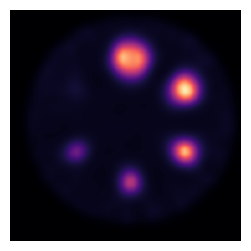

In [24]:
plt.figure(figsize=(3,3))
plt.imshow(reconstructed_image[:,:,64].cpu().T, cmap='magma', origin='lower', interpolation='Gaussian')
plt.xlim(40,85)
plt.ylim(40,85)
plt.axis('off')
plt.show()

## Save the images

`io.save_dicom` writes the reconstruction as a DICOM nuclear medicine (NM) file, placed by `object_meta`. SIMIND data have no patient, so the image is centred on the scanner's axis, where PyTomography reconstructs it (`object_meta.frame` is `'scanner'`). The reconstruction is in counts: SIMIND's projections were scaled to counts above.

In [25]:
saved = io.save_dicom(reconstructed_image, OUTPUT / 't_siminddata' / 'osem', object_meta, units='counts',
                      series_description='OSEM 4x8', overwrite=True)

In [26]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 0.39, "peak_ram_gb": 4.5}
